# Ensaios Mecânicos: Atividade III

Análise dos ensaios mecânicos realizados na máquina universal de ensaios (Instron, software Bluehill) da UFABC:

| Ensaio | Material | Corpo de prova | Arquivo |
|---|---|---|---|
| Tração | Aço SAE 1010 | Cilíndrico, $d_0$ = 6,4 mm, $L_0$ = 76,84 mm | `bruno.perciani.is_tens.raw` |
| Tração | Polipropileno (PP) | Retangular, 13,10 × 3,5 mm, $L_0$ = 60 mm | `bruno.perciani-polimero.is_tens.raw` |
| Flexão em 3 pontos | Cerâmica | Retangular, $b$ = 17,6 mm, $h$ = 8,5 mm, vão $L$ = 40 mm | `bruno.perciani.is_flex.raw` |

**Etapas do roteiro cobertas neste notebook**

| Etapa do roteiro | O que é feito | Seção |
|---|---|---|
| 3 e 5.2 | Leitura dos arquivos `.raw` e características dos corpos de prova | 2 |
| 4.1 e 5.3 | Tensão e deformação de engenharia e curvas σ × ε | 3, 4 e 5 |
| 4.2 a) | Módulo de elasticidade, $E$ | 6 |
| 4.2 c) | Limite de escoamento (0,2 % e pontos de escoamento) | 7 |
| 4.2 d) | Limite de resistência à tração, $\sigma_u$ | 8 |
| 4.2 b) e e) | Deformação na fratura e ductilidade (%AL) | 9 |
| 4.2 f) | Tensão verdadeira | 10 |
| 4.2 g) | Módulo de resiliência, $U_r$ | 11 |
| 4.2 h) | Módulo de tenacidade, $U_t$ | 12 |
| Flexão (cerâmica) | Resistência à flexão, módulo de flexão e deformação na fratura | 13 |
| 5.4 | Resumo dos resultados | 14 |

---

### Fundamentos: ensaios de tração e de flexão

No **ensaio de tração**, o corpo de prova (CP) é preso entre duas garras da máquina universal. A travessa móvel se afasta com velocidade constante e alonga o CP até a fratura, enquanto a **célula de carga** registra a força $F$ e o deslocamento da travessa registra o alongamento $\Delta L$. Esses valores são convertidos em **tensão** e **deformação**, que dependem apenas do material, e o gráfico entre elas é a **curva tensão-deformação**.

Materiais **frágeis**, como as cerâmicas, quase não se deformam plasticamente e são muito sensíveis a defeitos. Na tração, uma pequena desorientação nas garras já gera tensões de flexão e fratura prematura. Por isso a resistência das cerâmicas é medida no **ensaio de flexão**: o CP é apoiado em dois roletes e carregado no centro (3 pontos). A face inferior fica tracionada e a fratura começa nela.

**Observação importante sobre a deformação:** nestes ensaios não foi usado extensômetro. A deformação foi calculada pelo **deslocamento da travessa**, que inclui, além do alongamento do comprimento útil, a deformação elástica da máquina, das garras e das regiões fora do comprimento útil, além de eventuais escorregamentos. Isso afeta principalmente os módulos de elasticidade, como será discutido.

## 1. Bibliotecas e pasta dos dados

- `numpy`: cálculos numéricos com vetores;
- `pandas`: leitura dos arquivos e montagem das tabelas;
- `matplotlib`: gráficos;
- `scipy.signal.find_peaks`: localização dos picos e vales da curva (escoamento descontínuo do aço e trincas da cerâmica).

Os três arquivos `.raw` devem estar na pasta indicada em `PASTA`. As figuras e tabelas geradas são salvas na mesma pasta.

In [8]:
import os                              # caminhos de arquivos
import io                              # leitura de texto como arquivo
import numpy as np                     # cálculos numéricos
import pandas as pd                    # tabelas
import matplotlib.pyplot as plt        # gráficos
from scipy.signal import find_peaks    # picos e vales das curvas

%matplotlib inline

# Pasta com os arquivos .raw (ajuste para o seu computador)
PASTA = r"C:\Users\bruno\OneDrive\Visual Studio Code\2026.3\Materiais e suas Propriedades\Laboratório 03"

ARQ_ACO = os.path.join(PASTA, "bruno.perciani.is_tens.raw")
ARQ_PP  = os.path.join(PASTA, "bruno.perciani-polimero.is_tens.raw")
ARQ_CER = os.path.join(PASTA, "bruno.perciani.is_flex.raw")

g = 9.80665    # aceleração da gravidade (m/s²): converte kgf em N

from matplotlib.ticker import FuncFormatter
virg = lambda s: s.replace(".", ",")   # vírgula decimal nos rótulos dos gráficos
# vírgula decimal também nos números dos eixos
fmt_virg = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))
def eixos_virgula(ax):
    ax.xaxis.set_major_formatter(fmt_virg); ax.yaxis.set_major_formatter(fmt_virg)

## 2. Leitura dos arquivos `.raw` e geometria dos corpos de prova

Os arquivos exportados pelo Bluehill têm duas partes:

1. um **cabeçalho** com o tipo de ensaio, a geometria digitada no software e campos que não foram usados (valores padrão);
2. a **tabela de dados**, que começa na linha `"Time sec", ...`, com uma leitura a cada 0,1 s.

As colunas usadas são o tempo (s), o deslocamento da travessa (*Extension*, mm) e a carga (*Load*, **kgf**). As colunas de tensão e deformação calculadas pelo software estão zeradas, então todos os cálculos são feitos aqui. A carga é convertida para newtons:

$$F\,(\text{N}) = F\,(\text{kgf}) \cdot g, \qquad g = 9{,}80665\ \text{m/s}^2$$

No ensaio de flexão o software registra carga e deslocamento como negativos (compressão do rolete central). Por isso usamos as colunas *Flexure extension* e *Flexure load*, que já trazem os valores positivos.

As áreas das seções transversais são:

$$A_0^{\text{circular}} = \frac{\pi d_0^2}{4} \qquad\qquad A_0^{\text{retangular}} = b \cdot h$$

In [9]:
def ler_raw(arquivo):
    """Lê um arquivo .raw do Bluehill e devolve a tabela de dados como DataFrame."""
    with open(arquivo, encoding="utf-8", errors="replace") as f:
        linhas = f.read().splitlines()
    # a tabela começa na linha cujo primeiro campo é "Time sec"
    inicio = next(i for i, l in enumerate(linhas) if l.startswith('"Time sec"'))
    df = pd.read_csv(io.StringIO("\n".join(linhas[inicio:])))
    df.columns = [c.strip() for c in df.columns]      # remove espaços no fim dos nomes
    return df

aco = ler_raw(ARQ_ACO)
pp  = ler_raw(ARQ_PP)
cer = ler_raw(ARQ_CER)

for nome, df in [("Aço 1010", aco), ("PP", pp), ("Cerâmica", cer)]:
    print(f"{nome:9s}: {len(df):5d} pontos, duração {df['Time sec'].iloc[-1]:6.1f} s")

Aço 1010 :  1190 pontos, duração  118.9 s
PP       :  2951 pontos, duração  295.0 s
Cerâmica :   473 pontos, duração   47.1 s


In [10]:
# ---------- Geometria (dados informados pela docente) ----------
# Aço SAE 1010: CP cilíndrico
d0_aco = 6.4      # diâmetro inicial (mm)
L0_aco = 76.84    # distância entre as marcações do comprimento útil (mm)
v_aco  = 15       # velocidade da travessa (mm/min)

# Polipropileno: CP retangular
b_pp, h_pp = 13.10, 3.5   # largura e espessura iniciais (mm)
L0_pp = 60.0              # comprimento do CP usado como comprimento inicial (mm)
v_pp  = 80                # velocidade da travessa (mm/min)

# Cerâmica: flexão em 3 pontos
b_cer, h_cer = 17.6, 8.5  # largura e espessura (mm)
L_cer = 40.0              # distância entre os apoios (mm)

# ---------- Áreas (mm²) ----------
A0_aco = np.pi * d0_aco**2 / 4
A0_pp  = b_pp * h_pp

# ---------- Taxa de deformação nominal (s⁻¹) = velocidade / comprimento ----------
taxa_aco = v_aco / 60 / L0_aco
taxa_pp  = v_pp / 60 / L0_pp

# Velocidade real da travessa (inclinação do deslocamento × tempo), para conferência
for nome, df, col in [("Aço", aco, "Extension mm"), ("PP", pp, "Extension mm"), ("Cerâmica", cer, "Flexure extension mm")]:
    v = np.polyfit(df["Time sec"], df[col], 1)[0] * 60
    print(f"Velocidade medida da travessa ({nome}): {v:.2f} mm/min")

print(f"\nA0 aço = {A0_aco:.2f} mm²   taxa de deformação = {taxa_aco:.2e} s⁻¹")
print(f"A0 PP  = {A0_pp:.2f} mm²   taxa de deformação = {taxa_pp:.2e} s⁻¹")

Velocidade medida da travessa (Aço): 15.00 mm/min
Velocidade medida da travessa (PP): 80.00 mm/min
Velocidade medida da travessa (Cerâmica): 1.00 mm/min

A0 aço = 32.17 mm²   taxa de deformação = 3.25e-03 s⁻¹
A0 PP  = 45.85 mm²   taxa de deformação = 2.22e-02 s⁻¹


As duas taxas de deformação estão na faixa de 10⁻⁵ a 10⁻¹ s⁻¹ dos ensaios quase-estáticos. A velocidade medida no ensaio de flexão é **1 mm/min** (0,786 mm em 47 s), e não 1 mm/s.

## 3. Tensão e deformação de engenharia

$$\sigma = \frac{F}{A_0} \qquad\qquad \varepsilon = \frac{\Delta L}{L_0}$$

onde $\sigma$ é a tensão de engenharia (MPa = N/mm²), $F$ a carga (N), $A_0$ a área inicial (mm²), $\varepsilon$ a deformação de engenharia (adimensional), $\Delta L$ o deslocamento da travessa (mm) e $L_0$ o comprimento inicial (mm).

O último ponto de cada arquivo é registrado depois da ruptura (a carga cai bruscamente), então ele é descartado: o ponto de **fratura** é o último ponto antes dessa queda.

In [11]:
def tensao_deformacao(df, A0, L0):
    F = df["Load kgf"].to_numpy() * g          # carga (N)
    dL = df["Extension mm"].to_numpy()          # deslocamento da travessa (mm)
    F, dL = F[:-1], dL[:-1]                     # descarta o ponto registrado após a ruptura
    return F, dL, F / A0, dL / L0               # carga, alongamento, σ (MPa), ε

F_aco, dL_aco, s_aco, e_aco = tensao_deformacao(aco, A0_aco, L0_aco)
F_pp,  dL_pp,  s_pp,  e_pp  = tensao_deformacao(pp,  A0_pp,  L0_pp)

print(f"Aço: {len(s_aco)} pontos   σ máx = {s_aco.max():.1f} MPa   ε final = {100*e_aco[-1]:.1f} %")
print(f"PP : {len(s_pp)} pontos   σ máx = {s_pp.max():.1f} MPa   ε final = {100*e_pp[-1]:.0f} %")

Aço: 1189 pontos   σ máx = 458.3 MPa   ε final = 38.7 %
PP : 2950 pontos   σ máx = 29.1 MPa   ε final = 655 %


## 4. Curva tensão-deformação do aço SAE 1010

A curva do aço tem quatro regiões:

- **elástica:** trecho inicial, em que a deformação é reversível;
- **escoamento descontínuo:** típico de aços de baixo carbono. Os átomos de C e N intersticiais ancoram as discordâncias (atmosferas de Cottrell); é preciso uma tensão maior para liberá-las (**limite de escoamento superior**), e depois a deformação continua com tensão menor e oscilante (**limite de escoamento inferior**), enquanto as **bandas de Lüders** se propagam pelo comprimento útil;
- **encruamento:** a tensão volta a subir porque as discordâncias se multiplicam e se bloqueiam;
- **empescoçamento:** depois da carga máxima, a deformação se concentra em uma região, a área diminui localmente e a tensão de engenharia cai até a fratura.

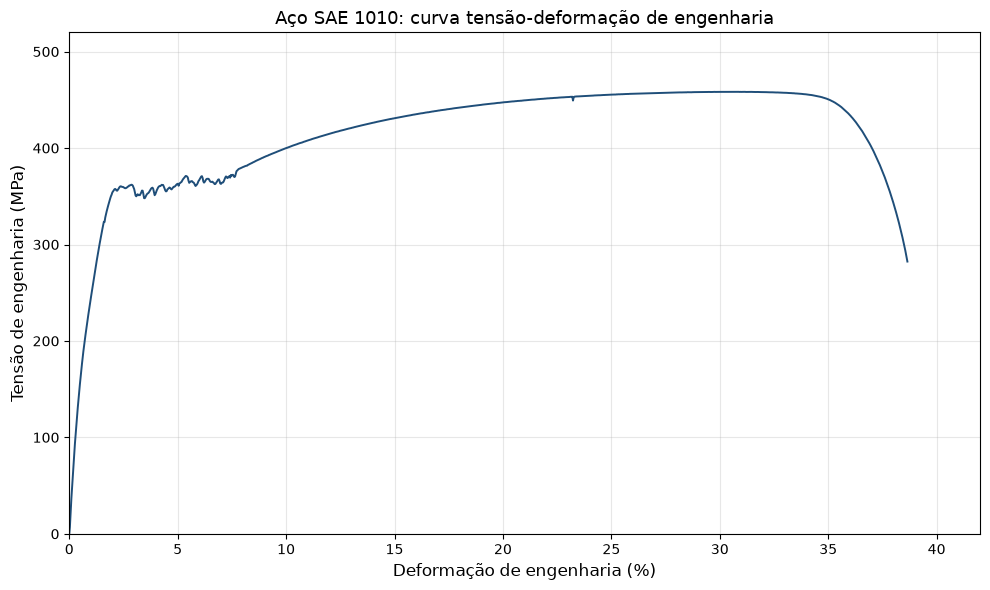

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(100 * e_aco, s_aco, color="#1f4e79", lw=1.4)
ax.set_xlabel("Deformação de engenharia (%)", fontsize=12)
ax.set_ylabel("Tensão de engenharia (MPa)", fontsize=12)
ax.set_title("Aço SAE 1010: curva tensão-deformação de engenharia", fontsize=13)
ax.set_xlim(0, 42); ax.set_ylim(0, 520)
ax.grid(alpha=0.3)
fig.tight_layout()
for a in fig.axes: eixos_virgula(a)
fig.savefig(os.path.join(PASTA, "aco_bruta.png"), dpi=300)
plt.show()

## 5. Curva tensão-deformação do polipropileno

O PP é um polímero semicristalino e sua curva é bem diferente da do aço:

- **região elástica** com módulo baixo (ligações secundárias entre as cadeias);
- **escoamento** em um pico de tensão, quando começa a formação do **pescoço**;
- queda de tensão e **estiramento a frio** (*cold drawing*): o pescoço se propaga ao longo do CP com tensão aproximadamente constante, enquanto as cadeias e as lamelas cristalinas se alinham na direção da carga;
- leve **endurecimento por orientação** no fim do ensaio, até a fratura com deformações de centenas de por cento.

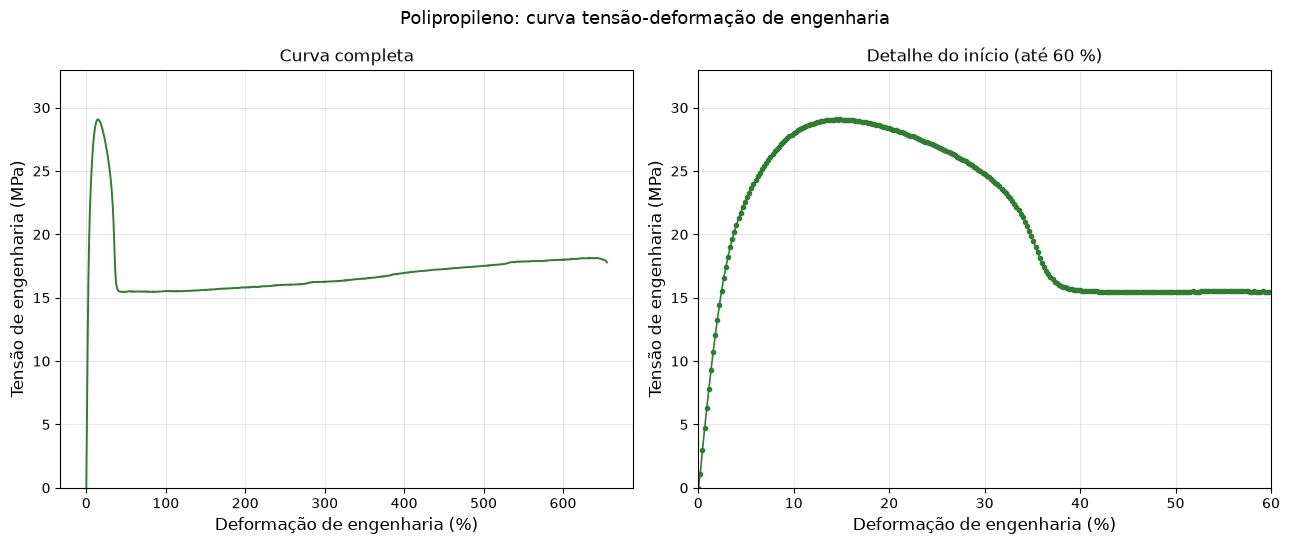

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
ax1.plot(100 * e_pp, s_pp, color="#2e7d32", lw=1.4)
ax1.set_title("Curva completa", fontsize=12)
ax2.plot(100 * e_pp, s_pp, "o-", color="#2e7d32", lw=1.2, ms=3)
ax2.set_xlim(0, 60)
ax2.set_title("Detalhe do início (até 60 %)", fontsize=12)
for ax in (ax1, ax2):
    ax.set_xlabel("Deformação de engenharia (%)", fontsize=12)
    ax.set_ylabel("Tensão de engenharia (MPa)", fontsize=12)
    ax.set_ylim(0, 33); ax.grid(alpha=0.3)
fig.suptitle("Polipropileno: curva tensão-deformação de engenharia", fontsize=13)
fig.tight_layout()
for a in fig.axes: eixos_virgula(a)
fig.savefig(os.path.join(PASTA, "pp_bruta.png"), dpi=300)
plt.show()

## 6. Módulo de elasticidade (item a)

Na região elástica vale a Lei de Hooke, $\sigma = E\varepsilon$. O módulo $E$ é a inclinação do trecho inicial, obtida por **regressão linear** dos pontos dentro de uma faixa de tensão:

- **aço:** entre 10 % e 40 % do limite de escoamento superior;
- **PP:** entre 10 % e 30 % da tensão de escoamento.

Como a deformação vem do deslocamento da travessa, o valor obtido é um **módulo aparente**. A rigidez medida é a combinação em série do CP com a máquina:

$$\frac{1}{k_{\text{medida}}} = \frac{1}{k_{\text{CP}}} + \frac{1}{k_{\text{máquina}}}, \qquad k_{\text{CP}} = \frac{E A_0}{L_0}$$

O aço tem $k_{\text{CP}}$ muito alto, então a flexibilidade da máquina domina e $E$ aparente fica muito abaixo do real (≈ 207 GPa [1]). O PP é cerca de 100 vezes mais flexível, então o erro é bem menor.

In [14]:
def modulo(s, e, s_ref, fmin, fmax):
    """Regressão linear σ × ε dos pontos iniciais com fmin·s_ref < σ < fmax·s_ref.
    Devolve E (MPa), o intercepto (MPa), o R² e a máscara dos pontos usados."""
    i_lim = np.argmax(s >= s_ref)                       # só a subida inicial
    m = np.zeros_like(s, dtype=bool)
    m[:i_lim] = (s[:i_lim] > fmin * s_ref) & (s[:i_lim] < fmax * s_ref)
    E, b = np.polyfit(e[m], s[m], 1)
    r2 = np.corrcoef(e[m], s[m])[0, 1]**2
    return E, b, r2, m

# Limite de escoamento superior do aço: primeiro pico da curva (ver seção 7)
pk, _ = find_peaks(s_aco, prominence=3)
i_ys = pk[0]
sigma_ys = s_aco[i_ys]

E_aco, b_aco, r2_aco, m_aco = modulo(s_aco, e_aco, sigma_ys, 0.10, 0.40)
E_pp,  b_pp,  r2_pp,  m_pp  = modulo(s_pp,  e_pp,  s_pp.max(), 0.10, 0.30)

E_lit_aco = 207e3   # módulo do aço da literatura (MPa) [1]

print(f"Aço: E aparente = {E_aco/1e3:.1f} GPa  ({m_aco.sum()} pontos, R² = {r2_aco:.4f})"
      f"  →  {100*E_aco/E_lit_aco:.0f} % do valor da literatura")
print(f"PP : E aparente = {E_pp/1e3:.2f} GPa  ({m_pp.sum()} pontos, R² = {r2_pp:.4f})")

# Rigidez da máquina estimada a partir do aço: 1/k_med = 1/k_CP + 1/k_maq
k_med = E_aco * A0_aco / L0_aco           # rigidez medida (N/mm)
k_cp  = E_lit_aco * A0_aco / L0_aco       # rigidez esperada do CP (N/mm)
k_maq = 1 / (1/k_med - 1/k_cp)
print(f"\nRigidez estimada do sistema máquina + garras: {k_maq/1e3:.1f} kN/mm")
print(f"Rigidez do CP de PP ({E_pp/1e3:.2f} GPa): {E_pp*A0_pp/L0_pp/1e3:.2f} kN/mm "
      f"→ erro pela máquina ≈ {100*(E_pp*A0_pp/L0_pp)/k_maq:.0f} %")

Aço: E aparente = 31.4 GPa  (11 pontos, R² = 0.9965)  →  15 % do valor da literatura
PP : E aparente = 0.72 GPa  (4 pontos, R² = 0.9997)

Rigidez estimada do sistema máquina + garras: 15.5 kN/mm
Rigidez do CP de PP (0.72 GPa): 0.55 kN/mm → erro pela máquina ≈ 4 %


## 7. Limite de escoamento (item c)

**Método do offset de 0,2 %:** traça-se uma reta paralela ao trecho elástico, com inclinação $E$, a partir de $\varepsilon$ = 0,002, e $\sigma_y$ é a tensão em que ela cruza a curva [1, 3]:

$$\sigma_{\text{reta}} = E\,(\varepsilon - 0{,}002) + b$$

onde $b$ é o intercepto da regressão, que corrige um pequeno deslocamento inicial da curva.

**Aço — escoamento descontínuo:** para materiais com patamar de escoamento, a norma ASTM E8 define o **limite de escoamento superior** ($\sigma_{ys}$, primeiro máximo antes do patamar) e o **inferior** ($\sigma_{yi}$, menor tensão no patamar). O Callister recomenda usar o inferior como limite de escoamento [1]. O fim do patamar é o primeiro ponto em que a tensão volta a superar $\sigma_{ys}$.

**PP:** em polímeros, o limite de escoamento é o **máximo local** da curva no início do empescoçamento (ISO 527 / ASTM D638). O offset de 0,2 % não se aplica, porque o trecho inicial já é não linear.

In [15]:
def offset_02(s, e, E, b):
    """Interseção da curva com a reta σ = E(ε − 0,002) + b (interpolação linear)."""
    gap = s - (E * (e - 0.002) + b)
    k = np.where((gap[:-1] > 0) & (gap[1:] <= 0))[0][0]    # curva passa para baixo da reta
    t = gap[k] / (gap[k] - gap[k+1])
    return s[k] + t * (s[k+1] - s[k]), e[k] + t * (e[k+1] - e[k])

# ---------- Aço ----------
sigma_02_aco, eps_02_aco = offset_02(s_aco, e_aco, E_aco, b_aco)

i_fim_pat = i_ys + np.argmax(s_aco[i_ys:] > sigma_ys)      # fim do patamar de Lüders
i_yi = i_ys + np.argmin(s_aco[i_ys:i_fim_pat])
sigma_yi = s_aco[i_yi]

print("Aço SAE 1010")
print(f"  Offset 0,2 % (E aparente):     σ_y  = {sigma_02_aco:.0f} MPa  (ε = {100*eps_02_aco:.2f} %)")
print(f"  Escoamento superior:           σ_ys = {sigma_ys:.0f} MPa  (ε = {100*e_aco[i_ys]:.2f} %)")
print(f"  Escoamento inferior:           σ_yi = {sigma_yi:.0f} MPa  (ε = {100*e_aco[i_yi]:.2f} %)")
print(f"  Patamar de Lüders: de {100*e_aco[i_ys]:.1f} % a {100*e_aco[i_fim_pat]:.1f} % de deformação")

# ---------- PP ----------
i_y_pp = np.argmax(s_pp)
sigma_y_pp, eps_y_pp = s_pp[i_y_pp], e_pp[i_y_pp]
print("\nPolipropileno")
print(f"  Tensão de escoamento (pico):   σ_y = {sigma_y_pp:.1f} MPa  (ε = {100*eps_y_pp:.1f} %)")

Aço SAE 1010
  Offset 0,2 % (E aparente):     σ_y  = 232 MPa  (ε = 0.91 %)
  Escoamento superior:           σ_ys = 362 MPa  (ε = 2.86 %)
  Escoamento inferior:           σ_yi = 348 MPa  (ε = 3.48 %)
  Patamar de Lüders: de 2.9 % a 4.9 % de deformação

Polipropileno
  Tensão de escoamento (pico):   σ_y = 29.1 MPa  (ε = 14.4 %)


## 8. Limite de resistência à tração (item d)

$$\sigma_u = \frac{F_{\text{máx}}}{A_0}$$

No PP a carga máxima coincide com o pico de escoamento, porque a tensão de estiramento a frio fica abaixo dele até a fratura. Também calculamos a **tensão média de estiramento** (patamar entre 100 % e 400 % de deformação) e a tensão na fratura.

In [16]:
i_u_aco = np.argmax(s_aco)
sigma_u_aco, eps_u_aco = s_aco[i_u_aco], e_aco[i_u_aco]

sigma_u_pp, eps_u_pp = sigma_y_pp, eps_y_pp
faixa = (e_pp > 1.0) & (e_pp < 4.0)
sigma_est_pp = s_pp[faixa].mean()             # tensão média de estiramento a frio

print(f"Aço: F_máx = {F_aco[i_u_aco]/1e3:.2f} kN   σ_u = {sigma_u_aco:.0f} MPa   (ε = {100*eps_u_aco:.1f} %)")
print(f"PP : F_máx = {F_pp[i_y_pp]:.0f} N   σ_u = {sigma_u_pp:.1f} MPa   (ε = {100*eps_u_pp:.1f} %)")
print(f"     tensão média de estiramento = {sigma_est_pp:.1f} MPa")
print(f"\nRazão σ_yi/σ_u do aço = {sigma_yi/sigma_u_aco:.2f}")

Aço: F_máx = 14.74 kN   σ_u = 458 MPa   (ε = 30.8 %)
PP : F_máx = 1333 N   σ_u = 29.1 MPa   (ε = 14.4 %)
     tensão média de estiramento = 16.1 MPa

Razão σ_yi/σ_u do aço = 0.76


## 9. Deformação na fratura e ductilidade (itens b e e)

A **deformação de engenharia na fratura** $\varepsilon_f$ é a do último ponto antes da ruptura. Ela inclui uma parcela elástica, que é recuperada quando o CP se rompe. O **alongamento percentual** (%AL) é a deformação **plástica** permanente [1]:

$$\%AL = 100\left(\varepsilon_f - \frac{\sigma_f}{E}\right)$$

onde $\sigma_f$ é a tensão de engenharia na fratura e $E$ o módulo aparente (a recuperação elástica da travessa também segue o módulo aparente).

**Redução de área (%RA):** exige o diâmetro (ou a seção) do CP medido após a fratura, que não foi informado. Se o grupo tiver essa medida, basta preencher `df_aco` abaixo.

In [17]:
# Aço
eps_f_aco, sigma_f_aco = e_aco[-1], s_aco[-1]
AL_aco = 100 * (eps_f_aco - sigma_f_aco / E_aco)

# PP
eps_f_pp, sigma_f_pp = e_pp[-1], s_pp[-1]
AL_pp = 100 * (eps_f_pp - sigma_f_pp / E_pp)

print(f"Aço: ε_f = {100*eps_f_aco:.1f} %   σ_f = {sigma_f_aco:.0f} MPa   %AL = {AL_aco:.1f} %")
print(f"PP : ε_f = {100*eps_f_pp:.0f} %   σ_f = {sigma_f_pp:.1f} MPa   %AL = {AL_pp:.0f} %")

# Redução de área: preencha o diâmetro final medido (mm), se houver
df_aco = None
if df_aco:
    Af_aco = np.pi * df_aco**2 / 4
    RA_aco = 100 * (A0_aco - Af_aco) / A0_aco
    print(f"Aço: %RA = {RA_aco:.1f} %")
else:
    print("\n%RA do aço não calculada: diâmetro final não informado.")

Aço: ε_f = 38.7 %   σ_f = 282 MPa   %AL = 37.8 %
PP : ε_f = 655 %   σ_f = 17.8 MPa   %AL = 653 %

%RA do aço não calculada: diâmetro final não informado.


## 10. Tensão e deformação verdadeiras (item f)

A tensão verdadeira usa a área instantânea, $\sigma_v = F/A_i$. Enquanto a deformação é **uniforme** (até a carga máxima), a conservação de volume ($A_0 L_0 = A_i L_i$) permite escrever:

$$\sigma_v = \sigma\,(1 + \varepsilon) \qquad\qquad \varepsilon_v = \ln(1 + \varepsilon)$$

Depois da carga máxima a deformação se concentra no pescoço e essas relações deixam de valer. A **tensão verdadeira na fratura** é $\sigma_{v,f} = F_f / A_f$ e exige a área final medida, que não foi informada. Por isso calculamos a tensão verdadeira **na carga máxima**.

Para o aço também estimamos o **expoente de encruamento** $n$ pelo critério de Considère: na carga máxima, $\varepsilon_v = n$.

Aço: σ_v na carga máxima = 600 MPa   ε_v = 0.269  →  n ≈ 0.27
PP : σ_v no escoamento   = 33.3 MPa   ε_v = 0.135


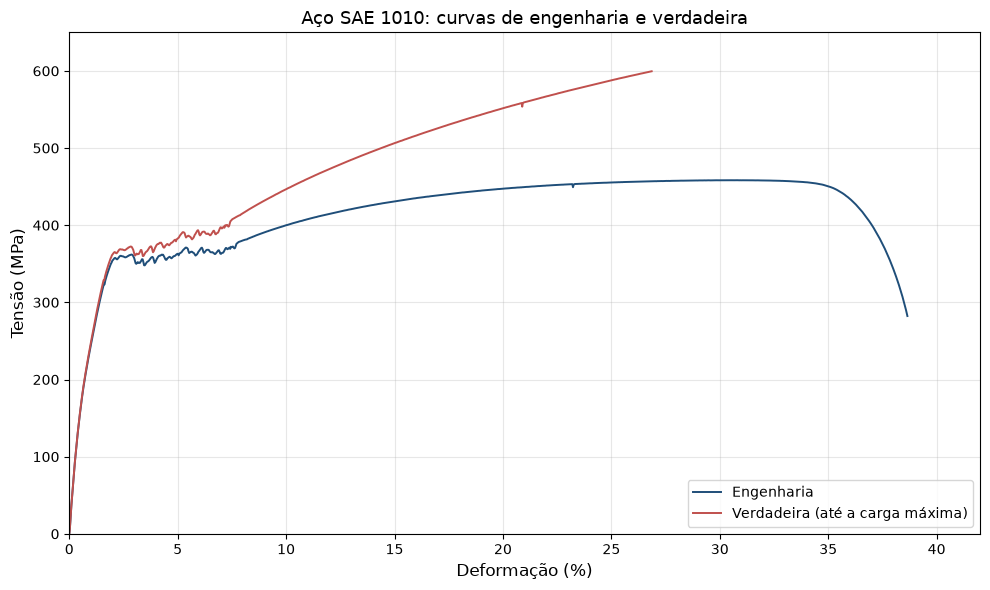

In [18]:
# Curva verdadeira do aço até a carga máxima
sv_aco = s_aco[:i_u_aco+1] * (1 + e_aco[:i_u_aco+1])
ev_aco = np.log(1 + e_aco[:i_u_aco+1])
sigma_vu_aco, eps_vu_aco = sv_aco[-1], ev_aco[-1]

sigma_vu_pp = sigma_u_pp * (1 + eps_u_pp)
eps_vu_pp = np.log(1 + eps_u_pp)

print(f"Aço: σ_v na carga máxima = {sigma_vu_aco:.0f} MPa   ε_v = {eps_vu_aco:.3f}  →  n ≈ {eps_vu_aco:.2f}")
print(f"PP : σ_v no escoamento   = {sigma_vu_pp:.1f} MPa   ε_v = {eps_vu_pp:.3f}")

if df_aco:
    print(f"Aço: σ_v,f = {F_aco[-1]/Af_aco:.0f} MPa")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(100 * e_aco, s_aco, color="#1f4e79", lw=1.4, label="Engenharia")
ax.plot(100 * ev_aco, sv_aco, color="#c0504d", lw=1.4, label="Verdadeira (até a carga máxima)")
ax.set_xlabel("Deformação (%)", fontsize=12); ax.set_ylabel("Tensão (MPa)", fontsize=12)
ax.set_title("Aço SAE 1010: curvas de engenharia e verdadeira", fontsize=13)
ax.set_xlim(0, 42); ax.set_ylim(0, 650); ax.grid(alpha=0.3); ax.legend(loc="lower right")
fig.tight_layout()
for a in fig.axes: eixos_virgula(a)
fig.savefig(os.path.join(PASTA, "aco_verdadeira.png"), dpi=300)
plt.show()

## 11. Módulo de resiliência (item g)

Energia elástica armazenada por unidade de volume até o escoamento (área do triângulo sob a reta elástica):

$$U_r = \frac{\sigma_y^2}{2E} \qquad (1\ \text{MPa} = 1\ \text{MJ/m}^3)$$

No aço, o $E$ aparente é cerca de 5 vezes menor que o real e inflaria $U_r$ na mesma proporção. Por isso $U_r$ do aço é calculado com o $E$ da literatura (207 GPa) e com $\sigma_{yi}$. No PP usa-se o $E$ medido.

In [19]:
Ur_aco     = sigma_yi**2 / (2 * E_lit_aco)
Ur_aco_ap  = sigma_yi**2 / (2 * E_aco)       # só para comparação
Ur_pp      = sigma_y_pp**2 / (2 * E_pp)

print(f"Aço: U_r = {Ur_aco*1e3:.0f} kJ/m³   (com E aparente seria {Ur_aco_ap*1e3:.0f} kJ/m³)")
print(f"PP : U_r = {Ur_pp*1e3:.0f} kJ/m³")

Aço: U_r = 293 kJ/m³   (com E aparente seria 1927 kJ/m³)
PP : U_r = 588 kJ/m³


## 12. Módulo de tenacidade (item h)

Energia absorvida até a fratura por unidade de volume: área sob a curva de engenharia, calculada pela **regra dos trapézios**:

$$U_t = \int_0^{\varepsilon_f}\sigma\,d\varepsilon \approx \sum_i \frac{\sigma_i + \sigma_{i+1}}{2}\,(\varepsilon_{i+1} - \varepsilon_i)$$

Para conferir, usa-se a aproximação de Callister para metais dúcteis [1]: $U_t \approx \frac{\sigma_y + \sigma_u}{2}\,\varepsilon_f$.

In [20]:
Ut_aco = np.trapezoid(s_aco, e_aco)
Ut_pp  = np.trapezoid(s_pp,  e_pp)
Ut_aco_aprox = (sigma_yi + sigma_u_aco) / 2 * eps_f_aco

print(f"Aço: U_t = {Ut_aco:.0f} MJ/m³   (aproximação de Callister: {Ut_aco_aprox:.0f} MJ/m³)")
print(f"PP : U_t = {Ut_pp:.0f} MJ/m³")

Aço: U_t = 160 MJ/m³   (aproximação de Callister: 156 MJ/m³)
PP : U_t = 112 MJ/m³


### Curvas finais com as propriedades indicadas

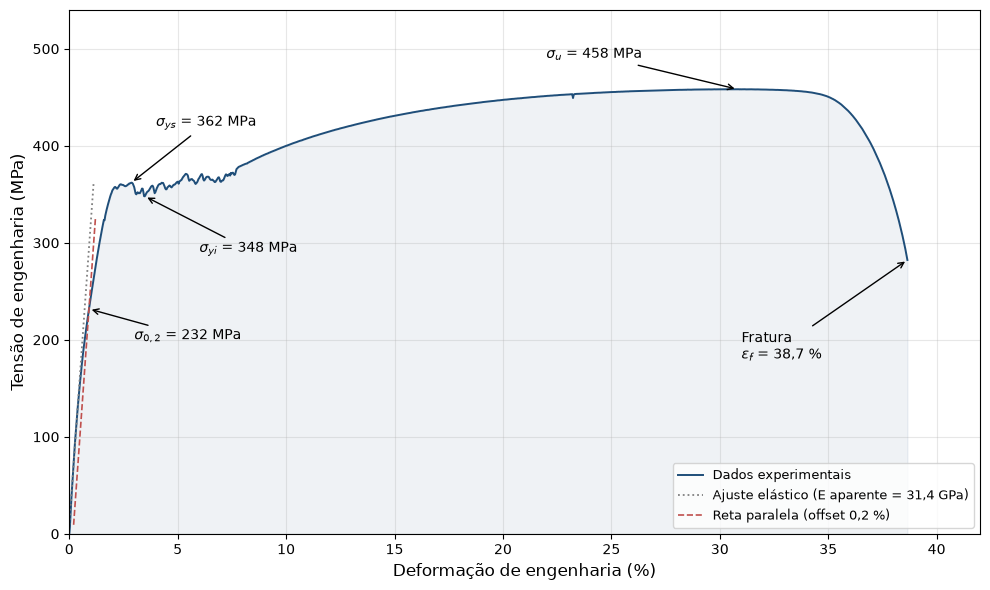

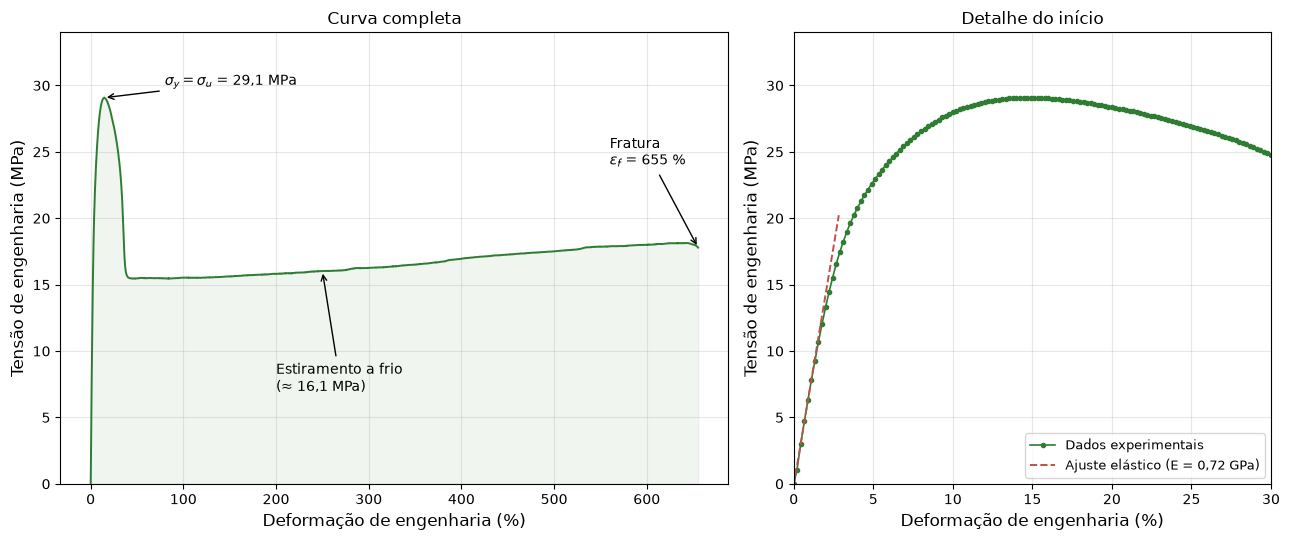

In [21]:
# ---------------- Aço ----------------
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(100 * e_aco, s_aco, color="#1f4e79", lw=1.4, label="Dados experimentais")
ax.fill_between(100 * e_aco, s_aco, color="#1f4e79", alpha=0.07)
e_el = np.linspace(0, (sigma_ys - b_aco) / E_aco, 20)
ax.plot(100 * e_el, E_aco * e_el + b_aco, ":", color="gray", lw=1.3,
        label=virg(f"Ajuste elástico (E aparente = {E_aco/1e3:.1f} GPa)"))
e_off = np.linspace(0.002, eps_02_aco + 0.003, 30)
ax.plot(100 * e_off, E_aco * (e_off - 0.002) + b_aco, "--", color="#c0504d", lw=1.2,
        label="Reta paralela (offset 0,2 %)")

ax.annotate(f"$\\sigma_{{ys}}$ = {sigma_ys:.0f} MPa", (100*e_aco[i_ys], sigma_ys), xytext=(4, 420),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate(f"$\\sigma_{{yi}}$ = {sigma_yi:.0f} MPa", (100*e_aco[i_yi], sigma_yi), xytext=(6, 290),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate(f"$\\sigma_{{0,2}}$ = {sigma_02_aco:.0f} MPa", (100*eps_02_aco, sigma_02_aco), xytext=(3, 200),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate(virg(f"$\\sigma_u$ = {sigma_u_aco:.0f} MPa"), (100*eps_u_aco, sigma_u_aco), xytext=(22, 490),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate(virg(f"Fratura\n$\\varepsilon_f$ = {100*eps_f_aco:.1f} %"), (100*eps_f_aco, sigma_f_aco),
            xytext=(31, 180), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("Deformação de engenharia (%)", fontsize=12)
ax.set_ylabel("Tensão de engenharia (MPa)", fontsize=12)
ax.set_xlim(0, 42); ax.set_ylim(0, 540); ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
for a in fig.axes: eixos_virgula(a)
fig.savefig(os.path.join(PASTA, "aco_propriedades.png"), dpi=300)
plt.show()

# ---------------- PP ----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.plot(100 * e_pp, s_pp, color="#2e7d32", lw=1.4)
ax1.fill_between(100 * e_pp, s_pp, color="#2e7d32", alpha=0.07)
ax1.annotate(virg(f"$\\sigma_y = \\sigma_u$ = {sigma_y_pp:.1f} MPa"), (100*eps_y_pp, sigma_y_pp),
             xytext=(80, 30), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax1.annotate(virg(f"Estiramento a frio\n(≈ {sigma_est_pp:.1f} MPa)"), (250, s_pp[np.argmin(abs(e_pp-2.5))]),
             xytext=(200, 7), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax1.annotate(virg(f"Fratura\n$\\varepsilon_f$ = {100*eps_f_pp:.0f} %"), (100*eps_f_pp, sigma_f_pp),
             xytext=(560, 24), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax1.set_title("Curva completa", fontsize=12)
ax2.plot(100 * e_pp, s_pp, "o-", color="#2e7d32", lw=1.2, ms=3, label="Dados experimentais")
e_el = np.linspace(0, 0.7 * sigma_y_pp / E_pp, 10)
ax2.plot(100 * e_el, E_pp * e_el + b_pp, "--", color="#c0504d", lw=1.4,
         label=virg(f"Ajuste elástico (E = {E_pp/1e3:.2f} GPa)"))
ax2.set_xlim(0, 30); ax2.set_title("Detalhe do início", fontsize=12); ax2.legend(loc="lower right", fontsize=9)
for ax in (ax1, ax2):
    ax.set_xlabel("Deformação de engenharia (%)", fontsize=12)
    ax.set_ylabel("Tensão de engenharia (MPa)", fontsize=12)
    ax.set_ylim(0, 34); ax.grid(alpha=0.3)
fig.tight_layout()
for a in fig.axes: eixos_virgula(a)
fig.savefig(os.path.join(PASTA, "pp_propriedades.png"), dpi=300)
plt.show()

## 13. Ensaio de flexão em 3 pontos da cerâmica

No ensaio de flexão em 3 pontos, o momento fletor máximo ocorre no centro do vão e a tensão de tração máxima está na face inferior do CP. Para uma seção retangular [1]:

$$\sigma = \frac{3 F L}{2 b h^2}$$

onde $F$ é a carga (N), $L$ a distância entre os apoios (mm), $b$ a largura e $h$ a espessura (mm). A **resistência à flexão** (módulo de ruptura) $\sigma_{fr}$ é essa tensão na carga máxima.

A **deformação na face tracionada** e o **módulo de flexão** são obtidos da deflexão $D$ no centro do vão (ASTM C1161 / D790):

$$\varepsilon = \frac{6 D h}{L^2} \qquad\qquad E_f = \frac{L^3 m}{4 b h^3}$$

onde $m$ é a inclinação (N/mm) do trecho linear da curva carga × deflexão.

**Início da curva:** até ≈ 0,34 mm de deslocamento a carga é praticamente nula, ou seja, o rolete ainda não estava apoiado no CP. A deflexão é medida a partir do **ponto de contato**, definido como o primeiro ponto com carga acima de 1 % da carga máxima.

**Inclinação $m$:** a curva fica mais rígida ao longo do ensaio, por acomodação e esmagamento local nos pontos de contato com os roletes. Por isso $m$ é a **maior inclinação** de uma regressão em janelas móveis de 10 pontos (1 s) antes da carga máxima. Como a deflexão vem da travessa, $E_f$ é um módulo aparente.

**Duas deformações na ruptura:** a deformação calculada pela deflexão desde o contato ($\varepsilon_{fr}$) inclui a acomodação e o dano acumulado. A parcela elástica pode ser estimada por $\varepsilon_{el} = \sigma_{fr}/E_f$.

**Trincas:** quedas bruscas de carga antes da ruptura final indicam trincas que se propagaram e foram detidas. Quedas consecutivas (separadas por menos de 0,01 mm) são agrupadas em um único evento, e só são consideradas as quedas maiores que 10 % da carga.

In [22]:
F_cer = cer["Flexure load kgf"].to_numpy()[:-1] * g     # carga (N), sem o ponto pós-ruptura
D_cer = cer["Flexure extension mm"].to_numpy()[:-1]     # deflexão (deslocamento do rolete, mm)

# Ponto de contato: primeiro ponto com carga acima de 1 % da carga máxima
i_max = np.argmax(F_cer)
i_c = np.argmax(F_cer > 0.01 * F_cer[i_max])
D_c = D_cer[i_c]
Dc = D_cer - D_c                      # deflexão a partir do contato (mm)

# Inclinação máxima em janelas móveis de 10 pontos, antes da carga máxima
J = 10
incl = np.array([np.polyfit(D_cer[i:i+J], F_cer[i:i+J], 1)[0] for i in range(i_c, i_max - J + 1)])
i_m = i_c + np.argmax(incl)
m_cer = incl.max()

# Tensão e deformação de flexão
s_cer = 3 * F_cer * L_cer / (2 * b_cer * h_cer**2)
e_cer = 6 * Dc * h_cer / L_cer**2

F_max = F_cer[i_max]
sigma_fr = s_cer[i_max]
eps_fr = e_cer[i_max]
E_f = L_cer**3 * m_cer / (4 * b_cer * h_cer**3)
eps_el = sigma_fr / E_f

# Trincas: agrupa quedas consecutivas e mantém as maiores que 10 %
quedas = np.where(np.diff(F_cer[:i_max+1]) < 0)[0]
eventos, k = [], 0
while k < len(quedas):
    ini = fim = quedas[k]
    while k + 1 < len(quedas) and D_cer[quedas[k+1]] - D_cer[fim] < 0.01:
        k += 1; fim = quedas[k]
    if F_cer[fim+1] < 0.90 * F_cer[ini]:
        eventos.append((ini, fim + 1))
    k += 1
queda = [ini for ini, fim in eventos]

print(f"Carga máxima            F_máx = {F_max:.0f} N ({F_max/g:.1f} kgf)")
print(f"Resistência à flexão    σ_fr  = {sigma_fr:.1f} MPa")
print(f"Inclinação máxima       m     = {m_cer:.0f} N/mm  (D = {D_cer[i_m]:.3f}–{D_cer[i_m+J-1]:.3f} mm)")
print(f"Módulo de flexão (aparente) E_f = {E_f/1e3:.1f} GPa")
print(f"Ponto de contato: D = {D_c:.3f} mm")
print(f"Deflexão desde o contato na ruptura = {Dc[i_max]:.3f} mm   →   ε_fr = {100*eps_fr:.2f} %")
print(f"Deformação elástica estimada  ε_el = σ_fr / E_f = {100*eps_el:.2f} %")
for n, (ini, fim) in enumerate(eventos, 1):
    print(f"Trinca {n}: D = {D_cer[ini]:.3f} mm, carga {F_cer[ini]:.0f} → {F_cer[fim]:.0f} N "
          f"({100*(1-F_cer[fim]/F_cer[ini]):.0f} %), σ = {s_cer[ini]:.1f} MPa")

Carga máxima            F_máx = 979 N (99.8 kgf)
Resistência à flexão    σ_fr  = 46.2 MPa
Inclinação máxima       m     = 7969 N/mm  (D = 0.767–0.781 mm)
Módulo de flexão (aparente) E_f = 11.8 GPa
Ponto de contato: D = 0.341 mm
Deflexão desde o contato na ruptura = 0.444 mm   →   ε_fr = 1.42 %
Deformação elástica estimada  ε_el = σ_fr / E_f = 0.39 %
Trinca 1: D = 0.507 mm, carga 240 → 215 N (10 %), σ = 11.3 MPa
Trinca 2: D = 0.542 mm, carga 352 → 210 N (40 %), σ = 16.6 MPa
Trinca 3: D = 0.709 mm, carga 661 → 575 N (13 %), σ = 31.2 MPa


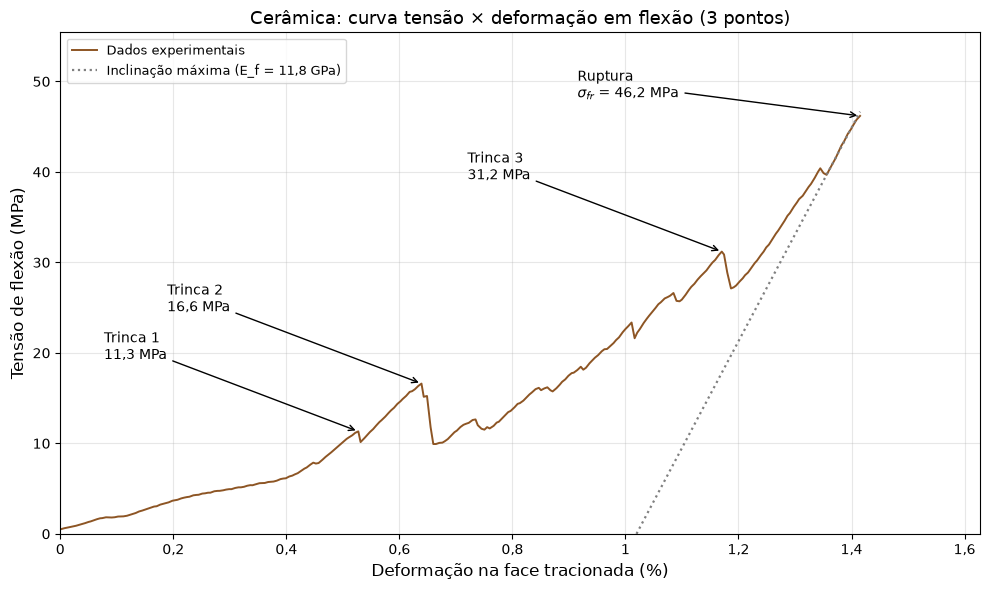

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
mask = Dc >= 0
ax.plot(100 * e_cer[mask], s_cer[mask], color="#8d5524", lw=1.4, label="Dados experimentais")
# reta com a inclinação máxima, passando pelo trecho em que ela foi medida
ee = np.linspace(e_cer[i_m] - s_cer[i_m] / E_f, eps_fr, 10)
ax.plot(100 * ee, s_cer[i_m] + E_f * (ee - e_cer[i_m]), ":", color="gray", lw=1.6,
        label=virg(f"Inclinação máxima (E_f = {E_f/1e3:.1f} GPa)"))
for n, k in enumerate(queda, 1):
    ax.annotate(virg(f"Trinca {n}\n{s_cer[k]:.1f} MPa"), (100*e_cer[k], s_cer[k]),
                xytext=(100*e_cer[k] - 0.45, s_cer[k] + 8), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate(virg(f"Ruptura\n$\\sigma_{{fr}}$ = {sigma_fr:.1f} MPa"), (100*eps_fr, sigma_fr),
            xytext=(100*eps_fr - 0.5, sigma_fr + 2), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("Deformação na face tracionada (%)", fontsize=12)
ax.set_ylabel("Tensão de flexão (MPa)", fontsize=12)
ax.set_title("Cerâmica: curva tensão × deformação em flexão (3 pontos)", fontsize=13)
ax.set_xlim(0, 100 * eps_fr * 1.15); ax.set_ylim(0, sigma_fr * 1.2)
ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
for a in fig.axes: eixos_virgula(a)
fig.savefig(os.path.join(PASTA, "ceramica_flexao.png"), dpi=300)
plt.show()

### Comparação entre os três materiais

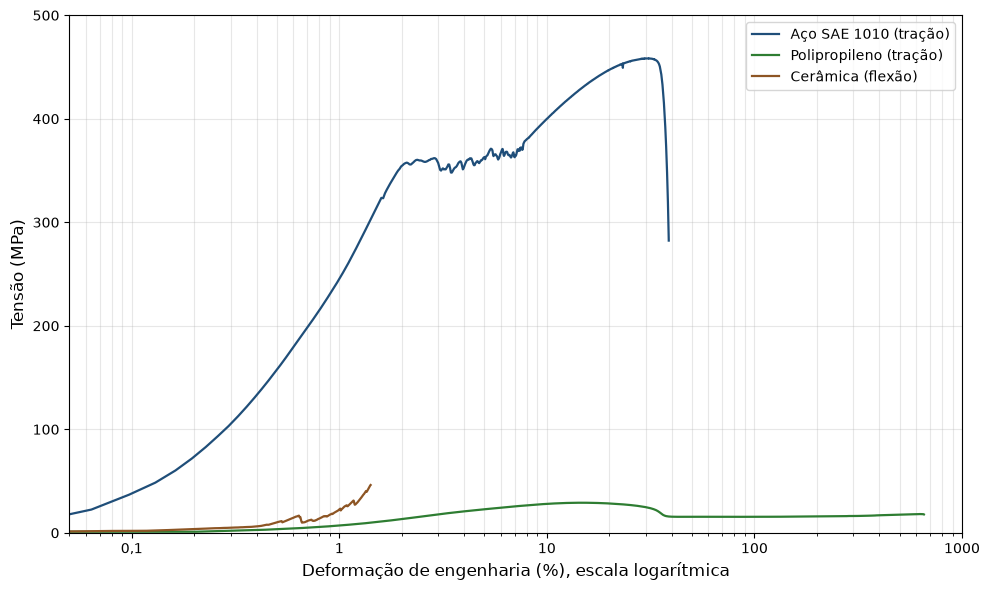

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(100 * e_aco, s_aco, color="#1f4e79", lw=1.6, label="Aço SAE 1010 (tração)")
ax.plot(100 * e_pp,  s_pp,  color="#2e7d32", lw=1.6, label="Polipropileno (tração)")
ax.plot(100 * e_cer[mask], s_cer[mask], color="#8d5524", lw=1.6, label="Cerâmica (flexão)")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(fmt_virg)
ax.set_xlabel("Deformação de engenharia (%), escala logarítmica", fontsize=12)
ax.set_ylabel("Tensão (MPa)", fontsize=12)
ax.set_xlim(0.05, 1000); ax.set_ylim(0, 500); ax.grid(alpha=0.3, which="both"); ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "comparacao.png"), dpi=300)
plt.show()

## 14. Resumo dos resultados

In [25]:
f = lambda v, d: f"{v:.{d}f}".replace(".", ",")
resumo = pd.DataFrame([
    ["a", "Módulo de elasticidade aparente, E (GPa)",         f(E_aco/1e3, 1), f(E_pp/1e3, 2)],
    ["c", "Limite de escoamento a 0,2 %, σ_0,2 (MPa)",        f(sigma_02_aco, 0), "não se aplica"],
    ["c", "Limite de escoamento superior, σ_ys (MPa)",        f(sigma_ys, 0), "—"],
    ["c", "Limite de escoamento inferior, σ_yi (MPa)",        f(sigma_yi, 0), "—"],
    ["c", "Tensão de escoamento (pico), σ_y (MPa)",           "—", f(sigma_y_pp, 1)],
    ["d", "Limite de resistência à tração, σ_u (MPa)",        f(sigma_u_aco, 0), f(sigma_u_pp, 1)],
    ["b", "Deformação de engenharia na fratura, ε_f (%)",     f(100*eps_f_aco, 1), f(100*eps_f_pp, 0)],
    ["e", "Alongamento, %AL (%)",                             f(AL_aco, 1), f(AL_pp, 0)],
    ["e", "Redução de área, %RA (%)",                         "d_f não informado", "—"],
    ["f", "Tensão verdadeira na carga máxima, σ_v (MPa)",     f(sigma_vu_aco, 0), f(sigma_vu_pp, 1)],
    ["g", "Módulo de resiliência, U_r (kJ/m³)",               f(Ur_aco*1e3, 0), f(Ur_pp*1e3, 0)],
    ["h", "Módulo de tenacidade, U_t (MJ/m³)",                f(Ut_aco, 0), f(Ut_pp, 0)],
], columns=["Item", "Propriedade", "Aço SAE 1010", "Polipropileno"])

flexao = pd.DataFrame([
    ["Carga máxima, F_máx (N)",                     f(F_max, 0)],
    ["Resistência à flexão, σ_fr (MPa)",            f(sigma_fr, 1)],
    ["Módulo de flexão aparente, E_f (GPa)",        f(E_f/1e3, 1)],
    ["Deformação na ruptura desde o contato, ε_fr (%)", f(100*eps_fr, 2)],
    ["Deformação elástica na ruptura, σ_fr/E_f (%)", f(100*eps_el, 2)],
] + [[f"Tensão na trinca {n}, (MPa)", f(s_cer[k], 1)] for n, k in enumerate(queda, 1)],
    columns=["Propriedade", "Cerâmica (flexão 3 pontos)"])

resumo.to_csv(os.path.join(PASTA, "resultados_tracao.csv"), sep=";", index=False, encoding="utf-8-sig")
flexao.to_csv(os.path.join(PASTA, "resultados_flexao.csv"), sep=";", index=False, encoding="utf-8-sig")
display(resumo)
display(flexao)

,Item,Propriedade,Aço SAE 1010,Polipropileno
0,a,"Módulo de elasticidade aparente, E (GPa)","31,4","0,72"
1,c,"Limite de escoamento a 0,2 %, σ_0,2 (MPa)",232,não se aplica
2,c,"Limite de escoamento superior, σ_ys (MPa)",362,—
3,c,"Limite de escoamento inferior, σ_yi (MPa)",348,—
4,c,"Tensão de escoamento (pico), σ_y (MPa)",—,"29,1"
5,d,"Limite de resistência à tração, σ_u (MPa)",458,"29,1"
6,b,"Deformação de engenharia na fratura, ε_f (%)","38,7",655
7,e,"Alongamento, %AL (%)","37,8",653
8,e,"Redução de área, %RA (%)",d_f não informado,—
9,f,"Tensão verdadeira na carga máxima, σ_v (MPa)",600,"33,3"


,Propriedade,Cerâmica (flexão 3 pontos)
0,"Carga máxima, F_máx (N)",979
1,"Resistência à flexão, σ_fr (MPa)","46,2"
2,"Módulo de flexão aparente, E_f (GPa)","11,8"
3,"Deformação na ruptura desde o contato, ε_fr (%)","1,42"
4,"Deformação elástica na ruptura, σ_fr/E_f (%)","0,39"
5,"Tensão na trinca 1, (MPa)","11,3"
6,"Tensão na trinca 2, (MPa)","16,6"
7,"Tensão na trinca 3, (MPa)","31,2"


**Interpretação**

- **Aço SAE 1010:** escoamento descontínuo com patamar de Lüders, típico de aço de baixo carbono, seguido de encruamento e empescoçamento. O material é dúctil e tenaz. O módulo aparente fica muito abaixo do real por causa da flexibilidade da máquina e das garras (seção 6).
- **Polipropileno:** módulo e resistência muito menores que os do aço, mas deformação na fratura cerca de 17 vezes maior, por causa do estiramento a frio. Por isso a tenacidade por volume fica na mesma ordem da do aço (≈ 110 contra ≈ 160 MJ/m³), mesmo com resistência ≈ 16 vezes menor.
- **Cerâmica:** comportamento frágil, sem deformação plástica e com deformação elástica na ruptura de apenas ≈ 0,4 %. As quedas de carga antes da ruptura indicam trincas que se formaram e foram detidas, o que é típico de cerâmicas porosas ou heterogêneas (por exemplo, cerâmica vermelha).

**Limitações:** deformações medidas pela travessa (sem extensômetro), um único CP por material e diâmetro e área finais não medidos.

**Referências**

[1] Callister, W. D. Jr.; Rethwisch, D. G. *Ciência e Engenharia de Materiais: uma introdução*. 10. ed. LTC, 2020.
[2] ASM Handbook, v. 8: *Mechanical Testing and Evaluation*. ASM International, 2000.
[3] ASTM E8/E8M-09. *Standard Test Methods for Tension Testing of Metallic Materials*. ASTM International, 2009.
[4] ASTM D638-10. *Standard Test Method for Tensile Properties of Plastics*. ASTM International, 2010.
[5] ASTM C1161. *Standard Test Method for Flexural Strength of Advanced Ceramics at Ambient Temperature*. ASTM International.